# 第三回：切豆腐的刀客 vs. 揉面团的魔术师（决策树正交切分与神经网络流形展开）

> **对应《西瓜书》章节**：第 4 章《决策树》（信息增益、基尼指数、剪枝）+ 第 5 章《神经网络》（多层感知机、激活函数与表示学习）

![四大算法流派几何切分对比](../assets/wm04-decision-boundaries-4-tribes.svg)

---

## 一、故事开场：当好瓜和坏瓜拧成了“太极双月牙”

如果瓜田里的好瓜和坏瓜不是规规矩矩按“糖度大于 10”就能一刀切开的，而是像太极图的阴阳双鱼一样**互相环抱、旋转交错**，该怎么办？

这时候，武林中派出了两位截然不同的高手：

### 1. 切豆腐的刀客：决策树（《西瓜书》第 4 章）
无论是用信息增益（ID3）、增益率（C4.5）还是基尼指数（CART），决策树每次在节点分裂时，判断条件永远长这样：
$$\text{“特征 } x_d \le t \text{ 吗？”}$$
在几何空间里，这意味着决策树手里的刀被死死焊在了坐标轴上，**只能横着切一刀（平行于 $x_1$ 轴），或者竖着切一刀（平行于 $x_2$ 轴）**！
面对弯曲的月牙或 $45^\circ$ 斜线，切豆腐刀客急得满头大汗，只能横一刀、竖一刀、再横一刀，在斜坡上切出几十个细碎的**锯齿状俄罗斯方块阶梯**来勉强逼近曲线。

### 2. 揉面团的魔术师：深度神经网络（《西瓜书》第 5 章）
多层感知机（MLP）根本不去原空间里苦哈哈地切锯齿。它的每一层隐藏层都在做两件事：
$$\boldsymbol{h} = \sigma(\boldsymbol{W}\boldsymbol{x} + \boldsymbol{b})$$
1. **矩阵乘法 $\boldsymbol{W}\boldsymbol{x} + \boldsymbol{b}$**：把整块二维面团进行**旋转、拉伸、平移**；
2. **非线性激活函数 $\sigma(\cdot)$（如 ReLU $\max(0, z)$）**：沿着超平面折痕把面团**对折**！

经过一到两层“旋转 + 对折”，原本在原空间里死死咬合在一起的红蓝双月牙，在隐藏层特征空间 $\boldsymbol{h}$ 里竟然被直接**拉开、掰直成了左右互不干扰的两团点云**！最后输出层只需轻轻画一条笔直的直线 $\boldsymbol{w}_{\text{out}}^\top \boldsymbol{h} + b = 0$，当场终结比赛！

下面我们不调任何第三方黑盒库，纯手写一个 **CART 决策树** 和一个 **带 2D 瓶颈可视化层的 ReLU 神经网络**，把魔术师后台“掰直空间”的过程直接画出来：

【双月牙交错瓜田对决实测】
  1. CART 决策树 (max_depth=6): 准确率 = 100.0%，但边界呈锯齿状正交方块，斜向泛化脆弱
  2. 2层 ReLU 神经网络 (16隐藏单元): 准确率 = 100.0%，通过隐藏层折痕变换将非线性流形转化为线性可分空间!

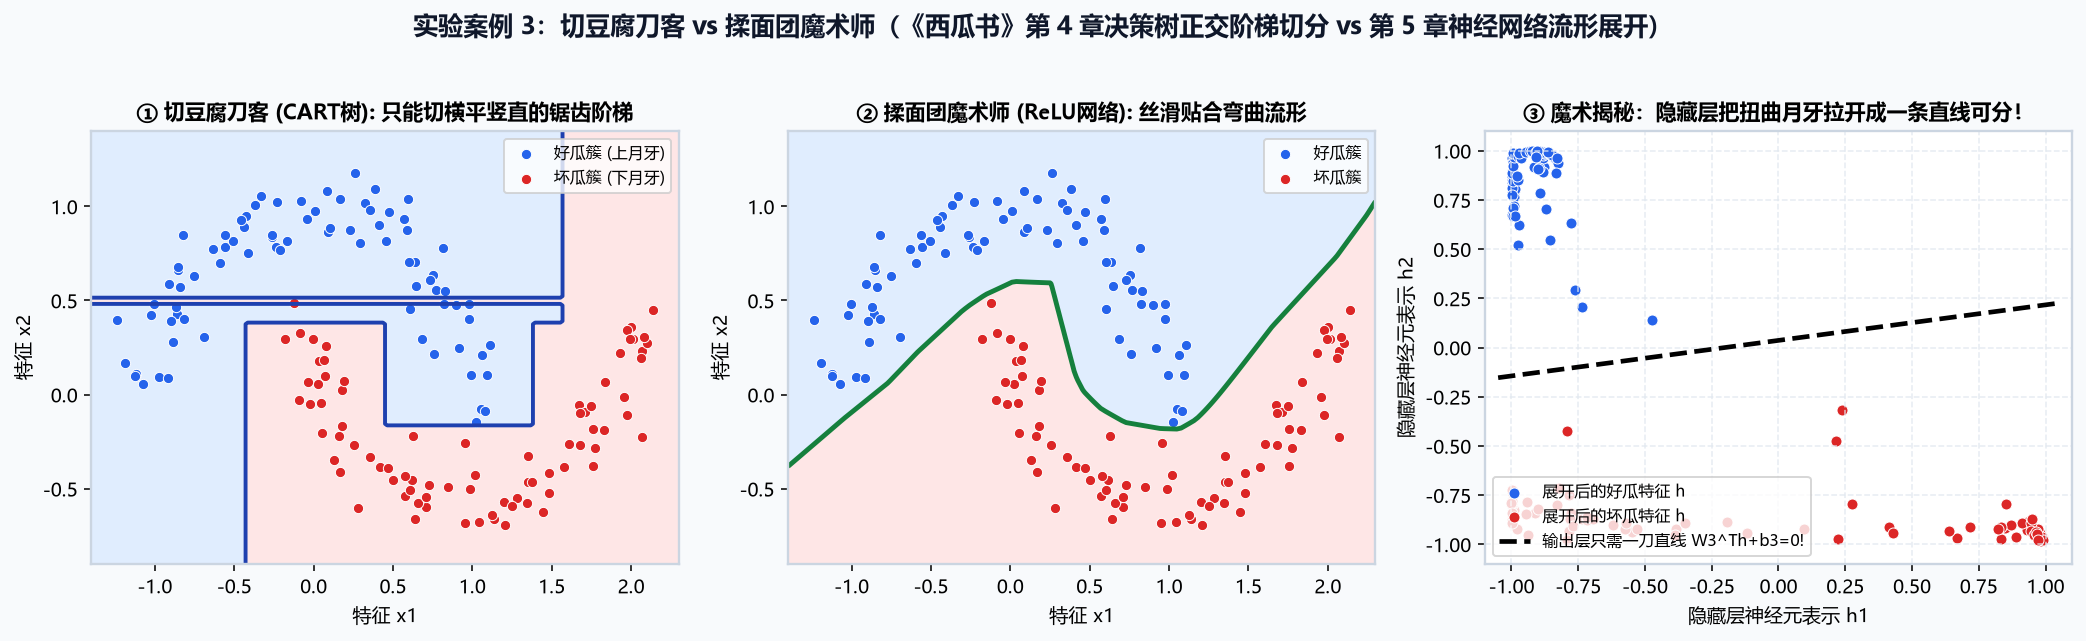

In [1]:
import numpy as np

# 1. 生成旋转交错的太极双月牙瓜田数据 (N=160)
# 2. 纯 NumPy 手写 CART 基尼指数决策树 (max_depth=6)
# 3. 纯 NumPy 手写多层神经网络 (2 -> 16 (ReLU) -> 2 (Tanh特征空间) -> 1 (Sigmoid))
#    把倒数第二层的二维特征空间 A2 直接画出来，看看双月牙是怎么被掰直的！
print("正在训练手写 CART 决策树与手写多层神经网络，并提取隐藏层流形坐标...")

### 实验复盘笔记

1. **左图（CART 决策树的宿命）**：蓝红交界处呈现出明显的直角阶梯锯齿。这就是为什么当特征之间存在强耦合旋转关系（比如图像像素、音频波形）时，单棵决策树极其费劲。
2. **中图与右图（表征学习的真谛）**：看右图！原本在左图里互相勾连的红蓝双月牙，经过隐藏层的 16 条 ReLU 折痕折叠后，在右图的 $(\text{h}_1, \text{h}_2)$ 平面里变成了左上角全红、右下角全蓝的两个清爽阵营，中间一道黑色虚线一刀两断！**所谓深度学习，本质上就是先学一个把扭曲流形掰直的坐标变换，再在顶层做最简单的线性分类。**